In [1]:
pip install pandas ccxt

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install schedule

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install plotly

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install ta


  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for ta: filename=ta-0.11.0-py3-none-any.whl size=29420 sha256=8fc44d07ae185cce05ee5565edd9ac64a372ad5d00f462780ba973512aa82796
  Stored in directory: c:\users\joseg\appdata\local\pip\cache\wheels\5c\a1\5f\c6b85a7d9452057be4ce68a8e45d77ba34234a6d46581777c6
Successfully built ta
Note: you may need to restart the kernel to use updated packages.


In [9]:
def fetch_top_cryptos(limit=40):
    url = "https://api.coingecko.com/api/v3/coins/markets"
    params = {
        "vs_currency": "usd",
        "order": "market_cap_desc",
        "per_page": limit,
        "page": 1,
        "sparkline": False
    }
    response = requests.get(url, params=params)
    data = response.json()
    
    if not exchange.symbols:
        exchange.load_markets()
        
    symbols = [coin["symbol"].upper() + "/USDT" for coin in data if coin["symbol"].upper() + "/USDT" in exchange.symbols]
    return symbols


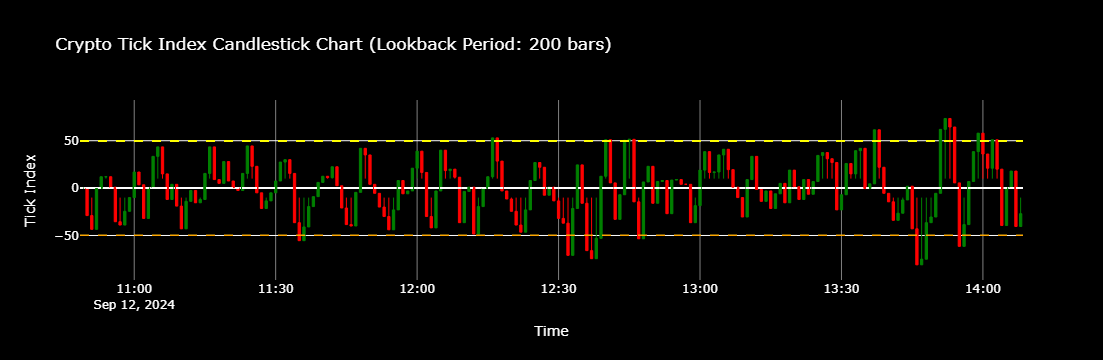

Exception in thread Thread-5 (run_scheduler):
Traceback (most recent call last):
  File "C:\Users\joseg\AppData\Roaming\Python\Python312\site-packages\urllib3\connectionpool.py", line 789, in urlopen
    response = self._make_request(
               ^^^^^^^^^^^^^^^^^^^
  File "C:\Users\joseg\AppData\Roaming\Python\Python312\site-packages\urllib3\connectionpool.py", line 536, in _make_request
    response = conn.getresponse()
               ^^^^^^^^^^^^^^^^^^
  File "C:\Users\joseg\AppData\Roaming\Python\Python312\site-packages\urllib3\connection.py", line 464, in getresponse
    httplib_response = super().getresponse()
                       ^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\joseg\anaconda3\Lib\http\client.py", line 1428, in getresponse
    response.begin()
  File "C:\Users\joseg\anaconda3\Lib\http\client.py", line 331, in begin
    version, status, reason = self._read_status()
                              ^^^^^^^^^^^^^^^^^^^
  File "C:\Users\joseg\anaconda3\Lib\http\client.py", 

In [1]:
import ccxt
import pandas as pd
import numpy as np
import plotly.graph_objs as go
from plotly.subplots import make_subplots
import schedule
import time
from IPython.display import display, clear_output

# Initialize the exchange
exchange = ccxt.binance()

# Load markets to ensure symbols are available
exchange.load_markets()

# Customizable lookback period
LOOKBACK_PERIOD = 200  # Adjust this value to set the lookback period

# Fetch the highest market cap USDT-paired cryptocurrencies
def fetch_highest_market_cap_symbols(limit=130):
    tickers = exchange.fetch_tickers()
    
    # Calculate market cap approximation (price * volume) for USDT pairs
    market_caps = {
        symbol: ticker['last'] * ticker['quoteVolume']
        for symbol, ticker in tickers.items()
        if symbol.endswith('/USDT') and ticker['quoteVolume'] is not None and ticker['last'] is not None
    }
    
    # Sort symbols by the calculated market cap and take the top 'limit' symbols
    sorted_symbols = sorted(market_caps, key=market_caps.get, reverse=True)
    return sorted_symbols[:limit]

# Function to fetch OHLCV data with a customizable lookback period
def fetch_ohlcv(symbol, timeframe='1m', limit=LOOKBACK_PERIOD):
    ohlcv = exchange.fetch_ohlcv(symbol, timeframe=timeframe, limit=limit)
    return ohlcv

# Function to calculate tick direction (1 for up, -1 for down, 0 for no change)
def calculate_tick(df):
    df['tick'] = np.sign(df['close'].diff()).fillna(0)
    return df

# Create the figure widget
fig = make_subplots(rows=1, cols=1)

def update_chart():
    # Fetch top market cap USDT-paired cryptos
    crypto_symbols = fetch_highest_market_cap_symbols(limit=100)

    # Fetch OHLCV data for all symbols
    data = {}
    for symbol in crypto_symbols:
        ohlcv = fetch_ohlcv(symbol)
        df = pd.DataFrame(ohlcv, columns=['timestamp', 'open', 'high', 'low', 'close', 'volume'])
        df['timestamp'] = pd.to_datetime(df['timestamp'], unit='ms')
        data[symbol] = df

    # Apply the tick calculation to all dataframes
    for symbol, df in data.items():
        data[symbol] = calculate_tick(df)

    # Create the combined DataFrame in one step
    tick_data = {'timestamp': data[crypto_symbols[0]]['timestamp']}
    for symbol, df in data.items():
        tick_data[symbol] = df['tick']

    # Convert dictionary to DataFrame
    tick_df = pd.DataFrame(tick_data)

    # Calculate the tick index (sum of ticks)
    tick_df['tick_index'] = tick_df[crypto_symbols].sum(axis=1)

    # Apply smoothing to the tick index
    smoothing_window = 2  # Adjust the window size as needed
    tick_df['smoothed_tick_index'] = tick_df['tick_index'].rolling(window=smoothing_window).mean().fillna(tick_df['tick_index'])

    # Calculate the high and low values within each interval
    tick_df['open'] = tick_df['smoothed_tick_index'].shift(1).fillna(tick_df['smoothed_tick_index'][0])
    tick_df['close'] = tick_df['smoothed_tick_index']

    # Using a larger rolling window for high and low calculations
    high_low_window = 2  # Adjust the window size as needed
    tick_df['high'] = tick_df['smoothed_tick_index'].rolling(window=high_low_window).max().fillna(tick_df['smoothed_tick_index'])
    tick_df['low'] = tick_df['smoothed_tick_index'].rolling(window=high_low_window).min().fillna(tick_df['smoothed_tick_index'])

    # Implement limits for extreme values
    extreme_limit = 10  # Example limit
    tick_df['high'] = tick_df['high'].clip(upper=extreme_limit)
    tick_df['low'] = tick_df['low'].clip(lower=-extreme_limit)

    # Clear the existing figure
    fig.data = []

    # Add candlestick trace for tick index with custom colors
    candlestick = go.Candlestick(
        x=tick_df['timestamp'],
        open=tick_df['open'],
        high=tick_df['high'],
        low=tick_df['low'],
        close=tick_df['close'],
        increasing_line_color='green',
        decreasing_line_color='red',
        increasing_fillcolor='green',
        decreasing_fillcolor='red',
        line=dict(width=1)  # Thin line for the high and low
    )

    fig.add_trace(candlestick, row=1, col=1)

    # Add horizontal lines at specified levels
    fig.add_hline(y=50, line=dict(color='yellow', width=1, dash='dash'), row=1, col=1)
    fig.add_hline(y=-50, line=dict(color='orange', width=1, dash='dash'), row=1, col=1)
    fig.add_hline(y=0, line=dict(color='white', width=1, dash='dot'), row=1, col=1)

    # Update layout for better visualization
    fig.update_layout(
        title=f'Crypto Tick Index Candlestick Chart (Lookback Period: {LOOKBACK_PERIOD} bars)',
        xaxis_title='Time',
        yaxis_title='Tick Index',
        xaxis_rangeslider_visible=False,
        yaxis=dict(
            range=[tick_df['tick_index'].min() - 10, tick_df['tick_index'].max() + 10]  # Dynamic range
        ),
        plot_bgcolor='black',
        paper_bgcolor='black',
        font=dict(color='white'),
        xaxis=dict(gridcolor='gray')
    )

    # Clear the previous output and display the updated figure
    clear_output(wait=True)
    display(fig)

# Schedule the chart to be updated every minute
schedule.every(1).minutes.do(update_chart)

# Flag to stop the scheduler
running = True

def run_scheduler():
    while running:
        schedule.run_pending()
        time.sleep(1)

def stop_scheduler():
    global running
    running = False

# Start the scheduler in a separate thread
import threading
scheduler_thread = threading.Thread(target=run_scheduler)
scheduler_thread.start()

# Initial chart update
update_chart()

# Example of stopping the scheduler after some time (e.g., 3 hours)
time.sleep(3 * 60 * 60)  # Run for 3 hours
stop_scheduler()
scheduler_thread.join()


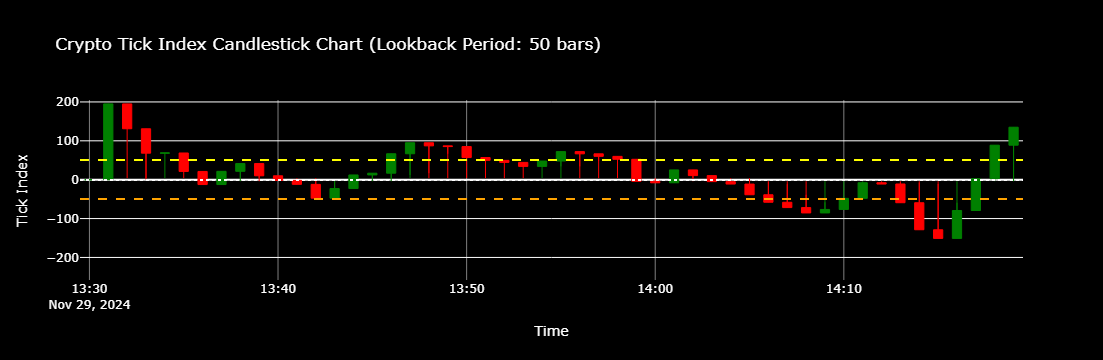

Exception in thread Thread-7 (run_scheduler):
Traceback (most recent call last):
  File "C:\Users\joseg\AppData\Roaming\Python\Python312\site-packages\urllib3\connectionpool.py", line 789, in urlopen
    response = self._make_request(
               ^^^^^^^^^^^^^^^^^^^
  File "C:\Users\joseg\AppData\Roaming\Python\Python312\site-packages\urllib3\connectionpool.py", line 536, in _make_request
    response = conn.getresponse()
               ^^^^^^^^^^^^^^^^^^
  File "C:\Users\joseg\AppData\Roaming\Python\Python312\site-packages\urllib3\connection.py", line 464, in getresponse
    httplib_response = super().getresponse()
                       ^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\joseg\anaconda3\Lib\http\client.py", line 1428, in getresponse
    response.begin()
  File "C:\Users\joseg\anaconda3\Lib\http\client.py", line 331, in begin
    version, status, reason = self._read_status()
                              ^^^^^^^^^^^^^^^^^^^
  File "C:\Users\joseg\anaconda3\Lib\http\client.py", 

In [ ]:
import ccxt
import pandas as pd
import numpy as np
import plotly.graph_objs as go
from plotly.subplots import make_subplots
import schedule
import time
from IPython.display import display, clear_output

# Initialize the exchange
exchange = ccxt.binance()

# Load markets to ensure symbols are available
exchange.load_markets()

# Customizable lookback period
LOOKBACK_PERIOD = 50  # Adjust this value to set the lookback period

# Function to fetch USDT-paired cryptocurrencies (all spot pairs)
def fetch_all_usdt_pairs():
    tickers = exchange.fetch_tickers()
    # Filter only USDT spot pairs
    usdt_pairs = [symbol for symbol in tickers if symbol.endswith('/USDT')]
    return usdt_pairs

# Function to fetch OHLCV data with a customizable lookback period
def fetch_ohlcv(symbol, timeframe='1m', limit=LOOKBACK_PERIOD):
    ohlcv = exchange.fetch_ohlcv(symbol, timeframe=timeframe, limit=limit)
    return ohlcv

# Function to calculate tick direction (1 for up, -1 for down, 0 for no change)
def calculate_tick(df):
    df['tick'] = np.sign(df['close'].diff()).fillna(0)
    return df

# Create the figure widget
fig = make_subplots(rows=1, cols=1)

def update_chart():
    # Fetch all USDT-paired cryptos
    crypto_symbols = fetch_all_usdt_pairs()

    # Fetch OHLCV data for all symbols
    data = {}
    for symbol in crypto_symbols:
        ohlcv = fetch_ohlcv(symbol)
        df = pd.DataFrame(ohlcv, columns=['timestamp', 'open', 'high', 'low', 'close', 'volume'])
        df['timestamp'] = pd.to_datetime(df['timestamp'], unit='ms')
        data[symbol] = df

    # Apply the tick calculation to all dataframes
    for symbol, df in data.items():
        data[symbol] = calculate_tick(df)

    # Create the combined DataFrame in one step
    tick_data = {'timestamp': data[crypto_symbols[0]]['timestamp']}
    for symbol, df in data.items():
        tick_data[symbol] = df['tick']

    # Convert dictionary to DataFrame
    tick_df = pd.DataFrame(tick_data)

    # Calculate the tick index (sum of ticks)
    tick_df['tick_index'] = tick_df[crypto_symbols].sum(axis=1)

    # Apply smoothing to the tick index
    smoothing_window = 4  # Adjust the window size as needed
    tick_df['smoothed_tick_index'] = tick_df['tick_index'].rolling(window=smoothing_window).mean().fillna(tick_df['tick_index'])

    # Calculate the high and low values within each interval
    tick_df['open'] = tick_df['smoothed_tick_index'].shift(1).fillna(tick_df['smoothed_tick_index'][0])
    tick_df['close'] = tick_df['smoothed_tick_index']

    # Using a larger rolling window for high and low calculations
    high_low_window = 4  # Adjust the window size as needed
    tick_df['high'] = tick_df['smoothed_tick_index'].rolling(window=high_low_window).max().fillna(tick_df['smoothed_tick_index'])
    tick_df['low'] = tick_df['smoothed_tick_index'].rolling(window=high_low_window).min().fillna(tick_df['smoothed_tick_index'])

    # Implement limits for extreme values
    extreme_limit = 4  # Example limit
    tick_df['high'] = tick_df['high'].clip(upper=extreme_limit)
    tick_df['low'] = tick_df['low'].clip(lower=-extreme_limit)

    # Clear the existing figure
    fig.data = []

    # Add candlestick trace for tick index with custom colors
    candlestick = go.Candlestick(
        x=tick_df['timestamp'],
        open=tick_df['open'],
        high=tick_df['high'],
        low=tick_df['low'],
        close=tick_df['close'],
        increasing_line_color='green',
        decreasing_line_color='red',
        increasing_fillcolor='green',
        decreasing_fillcolor='red',
        line=dict(width=1)  # Thin line for the high and low
    )

    fig.add_trace(candlestick, row=1, col=1)

    # Add horizontal lines at specified levels
    fig.add_hline(y=50, line=dict(color='yellow', width=1, dash='dash'), row=1, col=1)
    fig.add_hline(y=-50, line=dict(color='orange', width=1, dash='dash'), row=1, col=1)
    fig.add_hline(y=0, line=dict(color='white', width=1, dash='dot'), row=1, col=1)

    # Update layout for better visualization
    fig.update_layout(
        title=f'Crypto Tick Index Candlestick Chart (Lookback Period: {LOOKBACK_PERIOD} bars)',
        xaxis_title='Time',
        yaxis_title='Tick Index',
        xaxis_rangeslider_visible=False,
        yaxis=dict(
            range=[tick_df['tick_index'].min() - 10, tick_df['tick_index'].max() + 10]  # Dynamic range
        ),
        plot_bgcolor='black',
        paper_bgcolor='black',
        font=dict(color='white'),
        xaxis=dict(gridcolor='gray')
    )

    # Clear the previous output and display the updated figure
    clear_output(wait=True)
    display(fig)

# Schedule the chart to be updated every minute
schedule.every(1).minutes.do(update_chart)

# Flag to stop the scheduler
running = True

def run_scheduler():
    while running:
        schedule.run_pending()
        time.sleep(1)

def stop_scheduler():
    global running
    running = False

# Start the scheduler in a separate thread
import threading
scheduler_thread = threading.Thread(target=run_scheduler)
scheduler_thread.start()

# Initial chart update
update_chart()

# Example of stopping the scheduler after some time (e.g., 3 hours)
time.sleep(3 * 60 * 60)  # Run for 3 hours
stop_scheduler()
scheduler_thread.join()


In [ ]:
import ccxt
import pandas as pd
import numpy as np
import plotly.graph_objs as go
from plotly.subplots import make_subplots
import schedule
import time
from IPython.display import display, clear_output
import threading
from requests.exceptions import ConnectionError

# Initialize the exchange
exchange = ccxt.binance()

# Load markets to ensure symbols are available
exchange.load_markets()

# Customizable lookback period
LOOKBACK_PERIOD = 50  # Adjust this value to set the lookback period

# Retry helper function
def retry_with_backoff(func, max_retries=5, initial_delay=1, *args, **kwargs):
    retries = 0
    delay = initial_delay
    while retries < max_retries:
        try:
            return func(*args, **kwargs)
        except (ccxt.NetworkError, ccxt.ExchangeError, ConnectionError) as e:
            print(f"Error: {e}. Retrying in {delay} seconds...")
            time.sleep(delay)
            retries += 1
            delay *= 2  # Exponential backoff
    raise Exception("Max retries exceeded")

# Function to fetch USDT-paired cryptocurrencies (all spot pairs)
def fetch_all_usdt_pairs():
    return retry_with_backoff(
        lambda: [symbol for symbol in exchange.fetch_tickers() if symbol.endswith('/USDT')]
    )

# Function to fetch OHLCV data with a customizable lookback period
def fetch_ohlcv(symbol, timeframe='1m', limit=LOOKBACK_PERIOD):
    return retry_with_backoff(
        lambda: exchange.fetch_ohlcv(symbol, timeframe=timeframe, limit=limit)
    )

# Function to calculate tick direction (1 for up, -1 for down, 0 for no change)
def calculate_tick(df):
    df['tick'] = np.sign(df['close'].diff()).fillna(0)
    return df

# Create the figure widget
fig = make_subplots(rows=1, cols=1)

# Function to update the chart
def update_chart():
    try:
        # Fetch all USDT-paired cryptos
        crypto_symbols = fetch_all_usdt_pairs()

        # Fetch OHLCV data for all symbols
        data = {}
        for symbol in crypto_symbols:
            ohlcv = fetch_ohlcv(symbol)
            df = pd.DataFrame(ohlcv, columns=['timestamp', 'open', 'high', 'low', 'close', 'volume'])
            df['timestamp'] = pd.to_datetime(df['timestamp'], unit='ms')
            data[symbol] = df

        # Apply the tick calculation to all dataframes
        for symbol, df in data.items():
            data[symbol] = calculate_tick(df)

        # Create the combined DataFrame in one step
        tick_data = {'timestamp': data[crypto_symbols[0]]['timestamp']}
        for symbol, df in data.items():
            tick_data[symbol] = df['tick']

        # Convert dictionary to DataFrame
        tick_df = pd.DataFrame(tick_data)

        # Calculate the tick index (sum of ticks)
        tick_df['tick_index'] = tick_df[crypto_symbols].sum(axis=1)

        # Apply smoothing to the tick index
        smoothing_window = 4  # Adjust the window size as needed
        tick_df['smoothed_tick_index'] = tick_df['tick_index'].rolling(window=smoothing_window).mean().fillna(tick_df['tick_index'])

        # Calculate the high and low values within each interval
        tick_df['open'] = tick_df['smoothed_tick_index'].shift(1).fillna(tick_df['smoothed_tick_index'][0])
        tick_df['close'] = tick_df['smoothed_tick_index']
        high_low_window = 4  # Adjust the window size as needed
        tick_df['high'] = tick_df['smoothed_tick_index'].rolling(window=high_low_window).max().fillna(tick_df['smoothed_tick_index'])
        tick_df['low'] = tick_df['smoothed_tick_index'].rolling(window=high_low_window).min().fillna(tick_df['smoothed_tick_index'])

        # Implement limits for extreme values
        extreme_limit = 4
        tick_df['high'] = tick_df['high'].clip(upper=extreme_limit)
        tick_df['low'] = tick_df['low'].clip(lower=-extreme_limit)

        # Clear the existing figure
        fig.data = []

        # Add candlestick trace
        candlestick = go.Candlestick(
            x=tick_df['timestamp'],
            open=tick_df['open'],
            high=tick_df['high'],
            low=tick_df['low'],
            close=tick_df['close'],
            increasing_line_color='green',
            decreasing_line_color='red',
            line=dict(width=1)
        )
        fig.add_trace(candlestick, row=1, col=1)

        # Add horizontal lines
        fig.add_hline(y=50, line=dict(color='yellow', width=1, dash='dash'), row=1, col=1)
        fig.add_hline(y=-50, line=dict(color='orange', width=1, dash='dash'), row=1, col=1)
        fig.add_hline(y=0, line=dict(color='white', width=1, dash='dot'), row=1, col=1)

        # Update layout
        fig.update_layout(
            title=f'Crypto Tick Index Candlestick Chart (Lookback Period: {LOOKBACK_PERIOD} bars)',
            xaxis_title='Time',
            yaxis_title='Tick Index',
            xaxis_rangeslider_visible=False,
            yaxis=dict(
                range=[tick_df['tick_index'].min() - 10, tick_df['tick_index'].max() + 10]
            ),
            plot_bgcolor='black',
            paper_bgcolor='black',
            font=dict(color='white'),
            xaxis=dict(gridcolor='gray')
        )

        # Clear the output and display the updated figure
        clear_output(wait=True)
        display(fig)
    except Exception as e:
        print(f"Failed to update chart: {e}")

# Schedule the chart to update every minute
schedule.every(1).minutes.do(update_chart)

# Flag to control the scheduler
running = True

def run_scheduler():
    while running:
        schedule.run_pending()
        time.sleep(1)

def stop_scheduler():
    global running
    running = False

# Start the scheduler in a separate thread
scheduler_thread = threading.Thread(target=run_scheduler)
scheduler_thread.start()

# Initial chart update
update_chart()

# Stop the scheduler after 3 hours
time.sleep(3 * 60 * 60)  # Run for 3 hours
stop_scheduler()
scheduler_thread.join()


In [3]:
import ccxt
import pandas as pd
import numpy as np
import plotly.graph_objs as go
from plotly.subplots import make_subplots
import schedule
import time
from IPython.display import display, clear_output
import threading
from requests.exceptions import ConnectionError


In [ ]:
# Initialize the exchange
exchange = ccxt.binance()

# Load markets to ensure symbols are available
exchange.load_markets()

# Customizable lookback period
LOOKBACK_PERIOD = 100  # Adjust this value to set the lookback period

# Retry helper function
def retry_with_backoff(func, max_retries=5, initial_delay=1, *args, **kwargs):
    retries = 0
    delay = initial_delay
    while retries < max_retries:
        try:
            return func(*args, **kwargs)
        except (ccxt.NetworkError, ccxt.ExchangeError, ConnectionError) as e:
            print(f"Error: {e}. Retrying in {delay} seconds...")
            time.sleep(delay)
            retries += 1
            delay *= 2  # Exponential backoff
    raise Exception("Max retries exceeded")

# Function to fetch USDT-paired cryptocurrencies (all spot pairs)
def fetch_all_usdt_pairs():
    return retry_with_backoff(
        lambda: [symbol for symbol in exchange.fetch_tickers() if symbol.endswith('/USDT')]
    )

# Function to fetch OHLCV data with a customizable lookback period
def fetch_ohlcv(symbol, timeframe='1m', limit=LOOKBACK_PERIOD):
    return retry_with_backoff(
        lambda: exchange.fetch_ohlcv(symbol, timeframe=timeframe, limit=limit)
    )

# Function to calculate tick direction (1 for up, -1 for down, 0 for no change)
def calculate_tick(df):
    df['tick'] = np.sign(df['close'].diff()).fillna(0)
    return df

# Create the figure widget
fig = make_subplots(rows=1, cols=1)

# Function to update the chart
def update_chart():
    try:
        # Fetch all USDT-paired cryptos
        crypto_symbols = fetch_all_usdt_pairs()

        # Fetch OHLCV data for all symbols
        data = {}
        for symbol in crypto_symbols:
            ohlcv = fetch_ohlcv(symbol)
            df = pd.DataFrame(ohlcv, columns=['timestamp', 'open', 'high', 'low', 'close', 'volume'])
            df['timestamp'] = pd.to_datetime(df['timestamp'], unit='ms')
            data[symbol] = df

        # Apply the tick calculation to all dataframes
        for symbol, df in data.items():
            data[symbol] = calculate_tick(df)

        # Create the combined DataFrame in one step
        tick_data = {'timestamp': data[crypto_symbols[0]]['timestamp']}
        for symbol, df in data.items():
            tick_data[symbol] = df['tick']

        # Convert dictionary to DataFrame
        tick_df = pd.DataFrame(tick_data)

        # Calculate the tick index (sum of ticks)
        tick_df['tick_index'] = tick_df[crypto_symbols].sum(axis=1)

        # Apply smoothing to the tick index
        smoothing_window = 4  # Adjust the window size as needed
        tick_df['smoothed_tick_index'] = tick_df['tick_index'].rolling(window=smoothing_window).mean().fillna(tick_df['tick_index'])

        # Calculate the high and low values within each interval
        tick_df['open'] = tick_df['smoothed_tick_index'].shift(1).fillna(tick_df['smoothed_tick_index'][0])
        tick_df['close'] = tick_df['smoothed_tick_index']
        high_low_window = 4  # Adjust the window size as needed
        tick_df['high'] = tick_df['smoothed_tick_index'].rolling(window=high_low_window).max().fillna(tick_df['smoothed_tick_index'])
        tick_df['low'] = tick_df['smoothed_tick_index'].rolling(window=high_low_window).min().fillna(tick_df['smoothed_tick_index'])

        # Implement limits for extreme values
        extreme_limit = 4
        tick_df['high'] = tick_df['high'].clip(upper=extreme_limit)
        tick_df['low'] = tick_df['low'].clip(lower=-extreme_limit)

        # Clear the existing figure
        fig.data = []

        # Add candlestick trace
        candlestick = go.Candlestick(
            x=tick_df['timestamp'],
            open=tick_df['open'],
            high=tick_df['high'],
            low=tick_df['low'],
            close=tick_df['close'],
            increasing_line_color='green',
            decreasing_line_color='red',
            line=dict(width=1)
        )
        fig.add_trace(candlestick, row=1, col=1)

        # Add horizontal lines
        fig.add_hline(y=50, line=dict(color='yellow', width=1, dash='dash'), row=1, col=1)
        fig.add_hline(y=-50, line=dict(color='orange', width=1, dash='dash'), row=1, col=1)
        fig.add_hline(y=0, line=dict(color='white', width=1, dash='dot'), row=1, col=1)

        # Update layout
        fig.update_layout(
            title=f'Crypto Tick Index Candlestick Chart (Lookback Period: {LOOKBACK_PERIOD} bars)',
            xaxis_title='Time',
            yaxis_title='Tick Index',
            xaxis_rangeslider_visible=False,
            yaxis=dict(
                range=[tick_df['tick_index'].min() - 10, tick_df['tick_index'].max() + 10]
            ),
            plot_bgcolor='black',
            paper_bgcolor='black',
            font=dict(color='white'),
            xaxis=dict(gridcolor='gray')
        )

        # Clear the output and display the updated figure
        clear_output(wait=True)
        display(fig)
    except Exception as e:
        print(f"Failed to update chart: {e}")

# Schedule the chart to update every minute
schedule.every(1).minutes.do(update_chart)

# Flag to control the scheduler
running = True

def run_scheduler():
    while running:
        schedule.run_pending()
        time.sleep(1)

def stop_scheduler():
    global running
    running = False

# Start the scheduler in a separate thread
scheduler_thread = threading.Thread(target=run_scheduler)
scheduler_thread.start()

# Initial chart update
update_chart()

# Stop the scheduler after 3 hours
time.sleep(6 * 60 * 60)  # Run for 3 hours
stop_scheduler()
scheduler_thread.join()
